In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Problem 1

## Part A

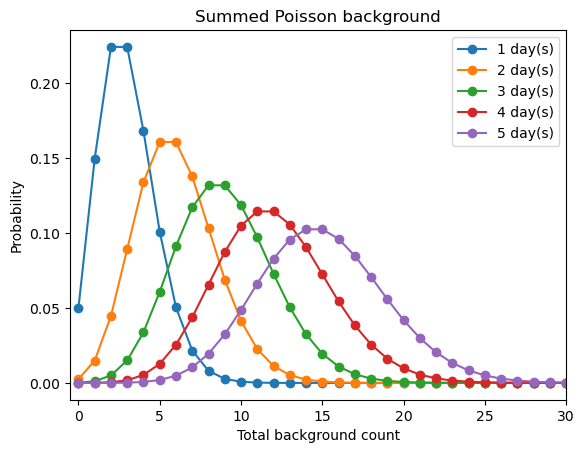

In [2]:
X = 3
k_max = 30
k = np.arange(k_max + 1)

P = stats.poisson.pmf(k, mu=X)
P_sum = P.copy()

fig, ax = plt.subplots()

for day in range(1, 6):
    if day > 1:
        P_sum = np.convolve(P_sum, P, mode='full')

    k_sum = np.arange(len(P_sum))
    ax.plot(k_sum, P_sum, 'o-',label=f'{day} day(s)')

ax.set(
    xlabel='Total background count',
    ylabel='Probability',
    title='Summed Poisson background'
)
ax.set_xlim(-0.5, k_max)
ax.legend()
plt.show()

## Part B

Let $A \sim \operatorname{Poisson}(\lambda_1)$ and $B \sim \operatorname{Poisson}(\lambda_2)$ be independent. The PMF of their sum is the convolution:

$$
\begin{aligned}
P(A+B=k)
&= \sum_{j=0}^{k} P(A=j)P(B=k-j) \\
&= \sum_{j=0}^{k}
\frac{e^{-\lambda_1}\lambda_1^j}{j!}
\frac{e^{-\lambda_2}\lambda_2^{k-j}}{(k-j)!} \\
&= \frac{e^{-(\lambda_1+\lambda_2)}}{k!}
\sum_{j=0}^{k}\binom{k}{j}\lambda_1^j\lambda_2^{k-j} \\
&= \frac{e^{-(\lambda_1+\lambda_2)}(\lambda_1+\lambda_2)^k}{k!}.
\end{aligned}
$$

By the binomial theorem, the convolution is a Poisson PMF with mean $\lambda_1+\lambda_2$:

$$
\boxed{A+B \sim \operatorname{Poisson}(\lambda_1+\lambda_2)}.
$$

For five independent days, each with mean background count $X$:

$$
\boxed{S_5 \sim \operatorname{Poisson}(5X)}.
$$

## Part C

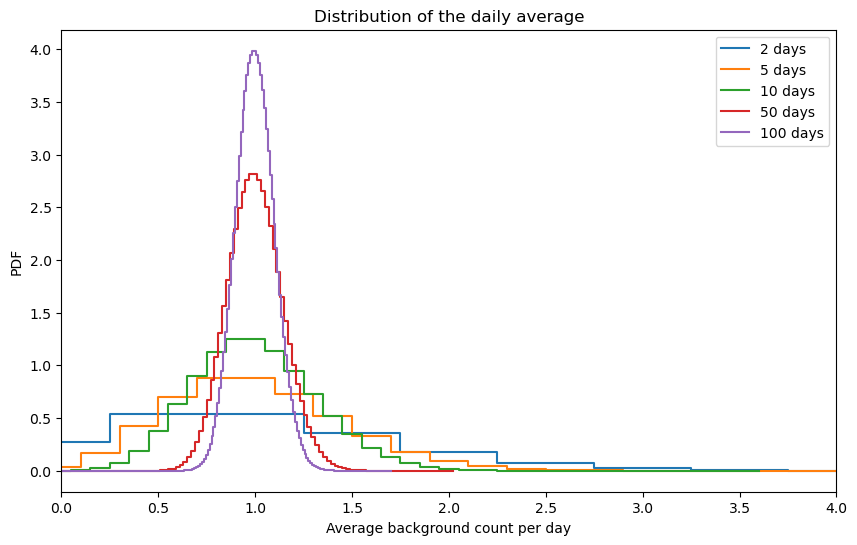

In [3]:
X = 1
days = [2, 5, 10, 50, 100]

fig, ax = plt.subplots(figsize=(10, 6))

for N in days:
    k_max = int(stats.poisson.ppf(1 - 1e-10, mu=N * X))
    k_sum = np.arange(k_max + 1)

    P_sum = stats.poisson.pmf(k_sum, mu=N * X)
    k_avg = k_sum / N

    ax.step(k_avg, N * P_sum, where='mid', label=f'{N} days')

ax.set(
    xlabel='Average background count per day',
    ylabel='PDF',
    title='Distribution of the daily average'
)
ax.set_xlim(0, 4)
ax.legend()
plt.show()

As the number of days $N$ increases, the average background count remains centered at $X$, while its standard deviation decreases as $\sqrt{X/N}$. The distribution therefore becomes narrower and less skewed. Averaging reduces fluctuations in the measured daily background.

In part B, the sum remains exactly Poisson:

$$
S_N \sim \operatorname{Poisson}(NX).
$$

The average is $A_N=S_N/N$, so it takes values $0,1/N,2/N,\ldots$ and is not itself Poisson. Its mean and variance are

$$
\mathbb{E}[A_N]=X,
\qquad
\operatorname{Var}(A_N)=\frac{X}{N}.
$$

By the central limit theorem, the standardized average converges in distribution to a standard Gaussian:

$$
\frac{A_N-X}{\sqrt{X/N}}
\xrightarrow{d}\mathcal{N}(0,1).
$$

Thus, for large $N$, the distribution of the average is approximately Gaussian:

$$
A_N \approx \mathcal{N}\left(X,\frac{X}{N}\right).
$$

This is consistent with part B: the sum remains exactly Poisson, while its shape becomes approximately Gaussian as its mean $NX$ grows.

## Part D

In [4]:
N = 50
X = 1
Y = 2

p = stats.poisson.sf(N * Y - 1, mu = N * X)
z = stats.norm.isf(p)

print("p-value:", p)
print("Significance:", z, "sigma")

p-value: 3.2000653245851495e-10
Significance: 6.180247198476331 sigma


The total count of noise over $N=50$ days follows

$$
S_{50} \sim \operatorname{Poisson}(NX)=\operatorname{Poisson}(50).
$$

The observed count is $NY=100$, much larger than the expected background count of $50$. The probability that background alone would produce this count or more is

$$
p=P(K\ge100)
=\sum_{k=100}^{\infty}\frac{e^{-50}50^k}{k!}.
$$

We convert this probability to an equivalent Gaussian significance:

$$
z=\Phi^{-1}(1-p).
$$

The resulting significance exceeds $5\sigma$, providing strong evidence against the background-only hypothesis and supporting the presence of a gamma-ray source.

# Problem 2

## Part A

Here we pick the Rayleigh distribution.

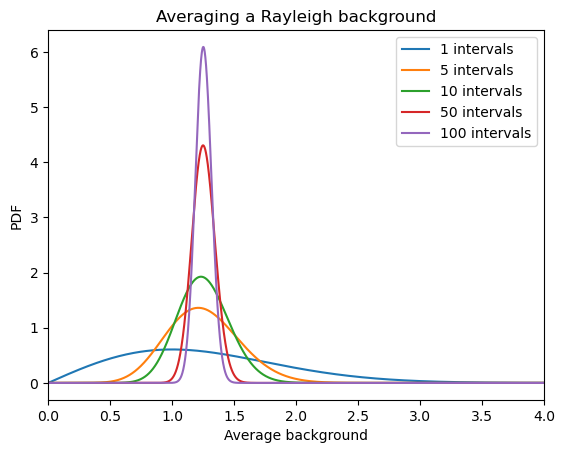

In [5]:
sigma = 1

x = np.linspace(0, 10, 1000)
dx = x[1] - x[0]

f = stats.rayleigh.pdf(x, scale=sigma)
p = f * dx
p /= p.sum()

num_ranges = [1, 5, 10, 50, 100]
fig, ax = plt.subplots()

for N in num_ranges:
    p_sum = p.copy()

    for _ in range(N - 1):
        p_sum = np.convolve(p_sum, p, mode='full')

    x_sum = N * x[0] + dx * np.arange(len(p_sum))
    x_avg = x_sum / N

    f_avg = p_sum / (dx / N)

    ax.plot(x_avg, f_avg, label=f'{N} intervals')

ax.set(
    xlabel='Average background',
    ylabel='PDF',
    title='Averaging a Rayleigh background'
)
ax.set_xlim(0, 4)
ax.legend()
plt.show()

The distribution gets narrower and looks more like a Gaussian as we average over more intervals. By about 50 intervals, it looks pretty close to a Gaussian.

We can show that the Rayleigh distribution has finite mean and variance, so the CLT applies.

For a Rayleigh distribution with $\sigma>0$,

$$
f(x)=\frac{x}{\sigma^2}e^{-x^2/(2\sigma^2)}, \qquad x\ge0.
$$

Using the substitution $u=x^2/(2\sigma^2)$, its moments are

$$
\begin{aligned}
\mathbb{E}[X^m]
&=\int_0^\infty x^m f(x)\,dx \\
&=\sigma^m 2^{m/2}\int_0^\infty u^{m/2}e^{-u}\,du \\
&=\sigma^m 2^{m/2}\Gamma\left(1+\frac{m}{2}\right).
\end{aligned}
$$

Thus,

$$
\mathbb{E}[X]=\sigma\sqrt{\frac{\pi}{2}},
\qquad
\mathbb{E}[X^2]=2\sigma^2.
$$

The variance is finite and positive:

$$
\operatorname{Var}(X)
=\mathbb{E}[X^2]-\mathbb{E}[X]^2
=\frac{4-\pi}{2}\sigma^2.
$$

Therefore, the CLT applies to the average of $N$ independent Rayleigh observations:

$$
\frac{\overline{X}_N-\sigma\sqrt{\pi/2}}
{\sigma\sqrt{(4-\pi)/(2N)}}
\xrightarrow{d}\mathcal{N}(0,1).
$$

For large $N$, the average is approximately Gaussian:

$$
\overline{X}_N
\approx
\mathcal{N}\left(
\sigma\sqrt{\frac{\pi}{2}},
\frac{(4-\pi)\sigma^2}{2N}
\right),
$$

where the second parameter denotes the variance.

# Problem 3

## Part A

In [6]:
X = 1
Y = 3.14

p = stats.norm.sf(Y, loc = 0, scale = X ** 2)
z = stats.norm.isf(p)

print(z)

3.14


For the values we pick, we can't claim a discovery.

## Part B

The question is:

Assuming there is only background noise, what is the probability that the brightest pixel has a brightness greater than $Y$?

The maximum brightness as

$$
B_{\max}=\max(B_1,\ldots,B_M).
$$

The maximum is below $b$ only if every pixel is below $b$. By independence, its CDF is

$$
\begin{aligned}
F_{\max}(b)
&=P(B_{\max}\le b) \\
&=\prod_{i=1}^{M}P(B_i\le b) \\
&=\left[\Phi\left(\frac{b}{X}\right)\right]^M.
\end{aligned},
$$
where $M = 10000$.

Its probability density:

$$
f_{\max}(b)
=\frac{M}{X}\phi\left(\frac{b}{X}\right)
\left[\Phi\left(\frac{b}{X}\right)\right]^{M-1},
$$

where $\Phi$ and $\phi$ are the standard Gaussian CDF and PDF. The PDF isn't a Gaussian distribution.

Therefore, the probability of finding at least one pixel with brightness $Y$ or greater is

$$
P(B_{\max}\ge Y)
=1-\left[\Phi\left(\frac{Y}{X}\right)\right]^M.
$$

## Part C

In [7]:
M = 10000
p = 1 - stats.norm.cdf(Y / X) ** M
z = stats.norm.isf(p)

print('Significance: ', z)

Significance:  -3.5225666100945734


# Problem 4

## Part A
The significance is $z = Y/X$, so
$$
Y = z X = 5.
$$

## Part B

To achieve a global significance of $5\sigma$, require

$$
P(B_{\max}\ge Y_M)
=1-\left[\Phi\left(\frac{Y_M}{X}\right)\right]^M
=p_5,
$$

where $p_5=1-\Phi(5)$.

Solving for the required signal strength gives

$$
\Phi\left(\frac{Y_M}{X}\right)=(1-p_5)^{1/M},
$$

so

$$
\boxed{Y_M=X\,\Phi^{-1}\left((1-p_5)^{1/M}\right)}.
$$

In [8]:
p5 = stats.norm.sf(5)
Y_M = X * stats.norm.ppf((1 - p5) ** (1 / M))

print("Required signal strength:", Y_M)
print('Ratio of brightness: ', Y_M  / 5)

Required signal strength: 6.550537486891655
Ratio of brightness:  1.310107497378331


## Part C

The required brightness ratio is about $1.31$, meaning the signal needs to be about $31\%$ brighter. This increase is relatively small because the Gaussian tail falls very quickly: an increase in brightness makes a background fluctuation much less likely, compensating for the $10{,}000$ trials.

## Part D

In [9]:
for M in [1, 100, 10_000, 1_000_000, 100_000_000]:
    p_local = -np.expm1(np.log1p(-p5) / M)
    threshold = stats.norm.isf(p_local)
    print(f"M = {M:>9}: Y/X = {threshold:.2f}")

M =         1: Y/X = 5.00
M =       100: Y/X = 5.82
M =     10000: Y/X = 6.55
M =   1000000: Y/X = 7.21
M = 100000000: Y/X = 7.81


As shown above, even changing the trials factor by several orders of magnitude only modestly increases the required signal strength.

## Extra

For any background distribution, the increase in the $5\sigma$ detection threshold depends on how quickly its upper tail falls. A rapidly falling tail gives a smaller sensitivity penalty, while a heavy tail gives a larger penalty. Here, $5\sigma$ means the same false-alarm probability as a $5\sigma$ Gaussian detection.